# Plot Correlation Results

This notebook plots the correlation results from `04_XROMY_event_analysis.py`.

## Notebook Overview
This notebook visualizes correlation metrics from event analyses to assess waveform agreement and quality.

**Main workflow**
- Load correlation result CSV files.
- Aggregate metrics by event/component/method.
- Plot correlation distributions and trends.
- Highlight robust vs weakly correlated cases.
- Save summary plots to `output/figures/correlation/` and `output/figures/publication/`.

## Imports

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

## Configuration

In [86]:
# CC threshold
cc_threshold = 0.1

# Specify path to correlation results
path_to_data = "./output/results_correlation.csv"

# Mark dates with reduced quality
dates_love = [20240915, 20250602, 20251206]
dates_rayleigh = [20240322, 20251206]

# Output directory for figures
output_dir = "./output/figures/correlation"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

## Load Data

In [87]:
# Load correlation results
df_cc = pd.read_csv(path_to_data)

print(f"Loaded {len(df_cc)} rows")
print(f"\nColumns: {list(df_cc.columns)}")
print(f"\nWave types: {df_cc['wave_type'].unique()}")
print(f"\nEvents: {df_cc['event_date'].unique()}")
df_cc.head()

Loaded 38 rows

Columns: ['event_date', 'origin_time', 'wave_type', 'cc_max', 'cc_max_lag', 'cc_zero', 'cc_zero_lag', 'backazimuth_theoretical', 'sampling_rate', 'rms_before_north', 'rms_after_north', 'rms_residual_north', 'var_reduction_north', 'rms_before_east', 'rms_after_east', 'rms_residual_east', 'var_reduction_east', 'rms_unit']

Wave types: ['love' 'rayleigh']

Events: [20190514 20230908 20230912 20231202 20240314 20240322 20240323 20240414
 20240422 20240815 20240915 20241023 20250513 20250602 20251206 20251212
 20251227 20260107 20260420]


,event_date,origin_time,wave_type,cc_max,cc_max_lag,cc_zero,cc_zero_lag,backazimuth_theoretical,sampling_rate,rms_before_north,rms_after_north,rms_residual_north,var_reduction_north,rms_before_east,rms_after_east,rms_residual_east,var_reduction_east,rms_unit
0,20190514,2019-05-14T12:58:25.939000Z,love,0.94,0,0.94,0,49.29,5.0,4.821988,4.850788,0.039890,-1.198126,4.765159,4.784608,0.034884,-0.817965,um/s2
1,20190514,2019-05-14T12:58:25.939000Z,rayleigh,0.95,-1,0.94,0,49.29,5.0,4.821988,4.850788,0.039890,-1.198126,4.765159,4.784608,0.034884,-0.817965,um/s2
2,20230908,2023-09-08T22:11:01.405000Z,love,0.96,0,0.96,0,228.40,5.0,9.601712,9.619776,0.033026,-0.376624,8.682311,8.711555,0.048855,-0.674777,um/s2
3,20230908,2023-09-08T22:11:01.405000Z,rayleigh,0.96,1,0.95,0,228.40,5.0,9.601712,9.619776,0.033026,-0.376624,8.682311,8.711555,0.048855,-0.674777,um/s2
4,20230912,2023-09-12T11:03:17.243000Z,love,0.96,0,0.96,0,62.52,5.0,0.287479,0.288305,0.001652,-0.575907,0.262718,0.263500,0.001895,-0.595948,um/s2


## Cross-Correlation Comparison

Compare cross-correlation with zero lag vs maximum correlation (with lag correction).

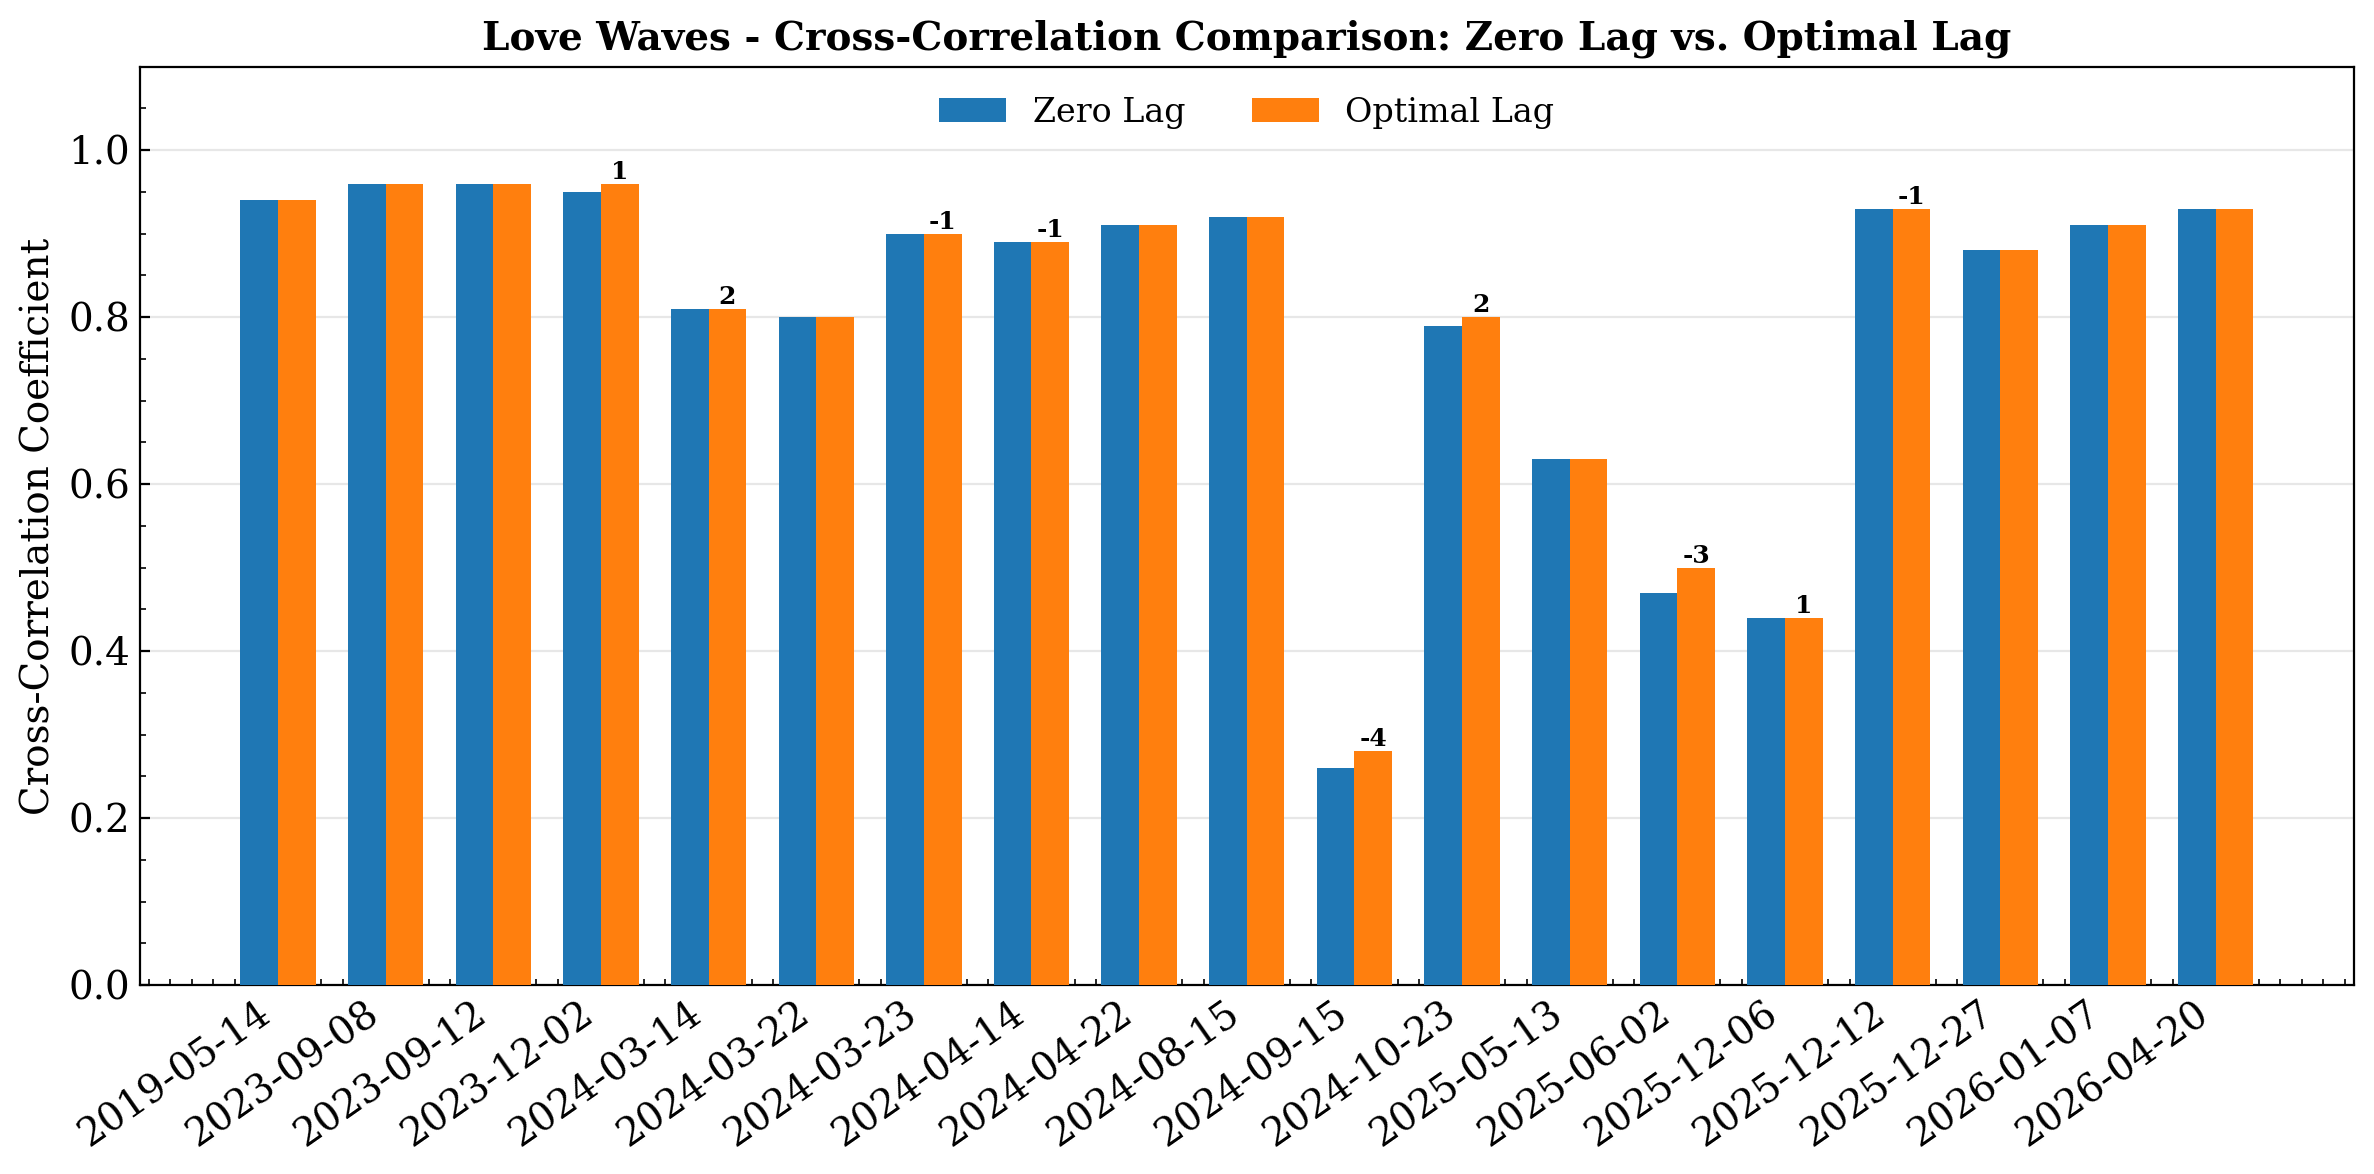

Saved: ./output/figures/correlation_comparison_love.png


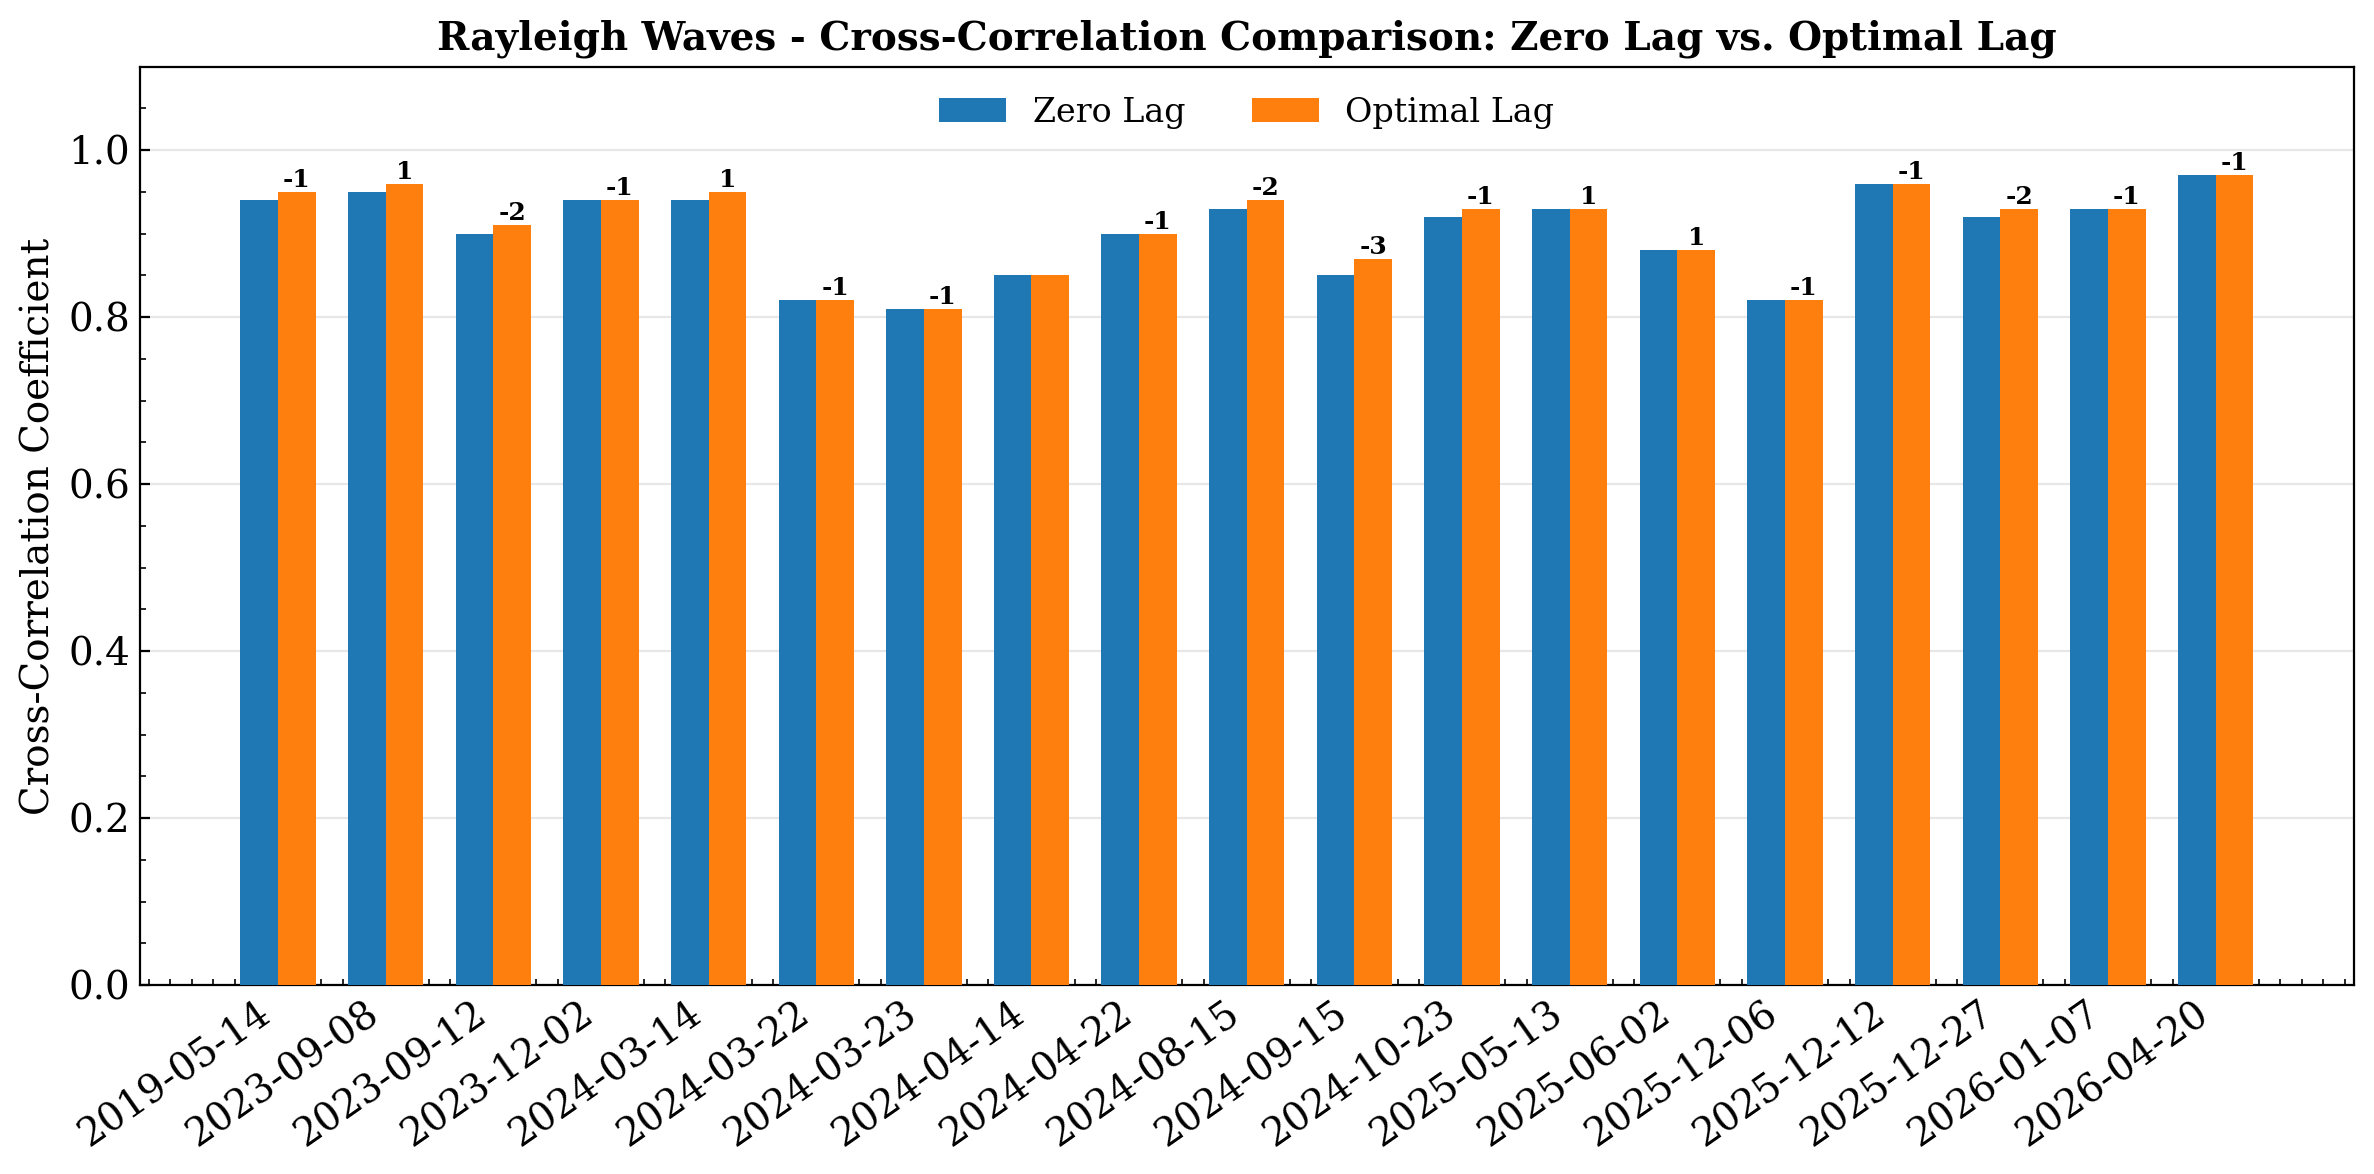

Saved: ./output/figures/correlation_comparison_rayleigh.png


In [88]:
# Create separate plots for each wave type
wave_types = df_cc['wave_type'].unique()

for wave_type in wave_types:
    df_wave = df_cc[df_cc['wave_type'] == wave_type].copy()
    
    if len(df_wave) == 0:
        continue
    
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Filter out NaN values
    valid_data = df_wave.dropna(subset=['cc_zero', 'cc_max', 'cc_max_lag'])
    
    if len(valid_data) == 0:
        print(f"No valid data for {wave_type}")
        continue
    
    x = np.arange(len(valid_data))
    width = 0.35
    
    # Plot CC threshold
    # ax.axhline(y=cc_threshold, color='gray', linestyle='--', linewidth=1.5, label='CC threshold', zorder=0)
    
    # Plot all bars
    bars1 = ax.bar(x - width/2, valid_data['cc_zero'], width, zorder=10,
                label='Zero Lag', alpha=1, color='tab:blue', edgecolor='none')
    bars2 = ax.bar(x + width/2, valid_data['cc_max'], width, zorder=10,
                label='Optimal Lag', alpha=1, color='tab:orange', edgecolor='none')
    
    # Add text in bar with lag samples (for maximum correlation bars)
    for i, bar in enumerate(bars2):
        lag_val = valid_data['cc_max_lag'].iloc[i]
        if not np.isnan(lag_val) and lag_val != 0:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), 
                    f"{lag_val:.0f}",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax.set_ylabel('Cross-Correlation Coefficient', fontsize=14)
    ax.set_title(f'{wave_type.capitalize()} Waves - Cross-Correlation Comparison: Zero Lag vs. Optimal Lag', 
                 fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    xlables = [str(l)[:4]+"-"+str(l)[4:6]+"-"+str(l)[6:] for l in valid_data['event_date'].values]
    ax.set_xticklabels(xlables, rotation=35, ha='right', fontsize=14)
    ax.legend(fontsize=12, loc=9, ncol=2)
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 1.1)
    ax.tick_params(axis='both', which='major', labelsize=14)
    
    plt.tight_layout()
    plt.show()
    
    output_file = os.path.join(output_dir, f'correlation_comparison_{wave_type}.png')
    fig.savefig(output_file, bbox_inches='tight', dpi=150)
    print(f"Saved: {output_file}")

## Publication Plots

One bar group per event: tilt artefact RMS as a percentage of RMS before correction
(`100 × RMS_residual / RMS_before`) for $a_N$ and $a_E$.

In [89]:
output_dir = "./output/figures/publication"
os.makedirs(output_dir, exist_ok=True)

# Publication-style defaults
plt.rcParams.update({
    "font.size": 11,
    "font.family": "serif",
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "ytick.minor.visible": True,
    "xtick.minor.visible": True,
    "legend.frameon": False,
    "figure.dpi": 200,
})

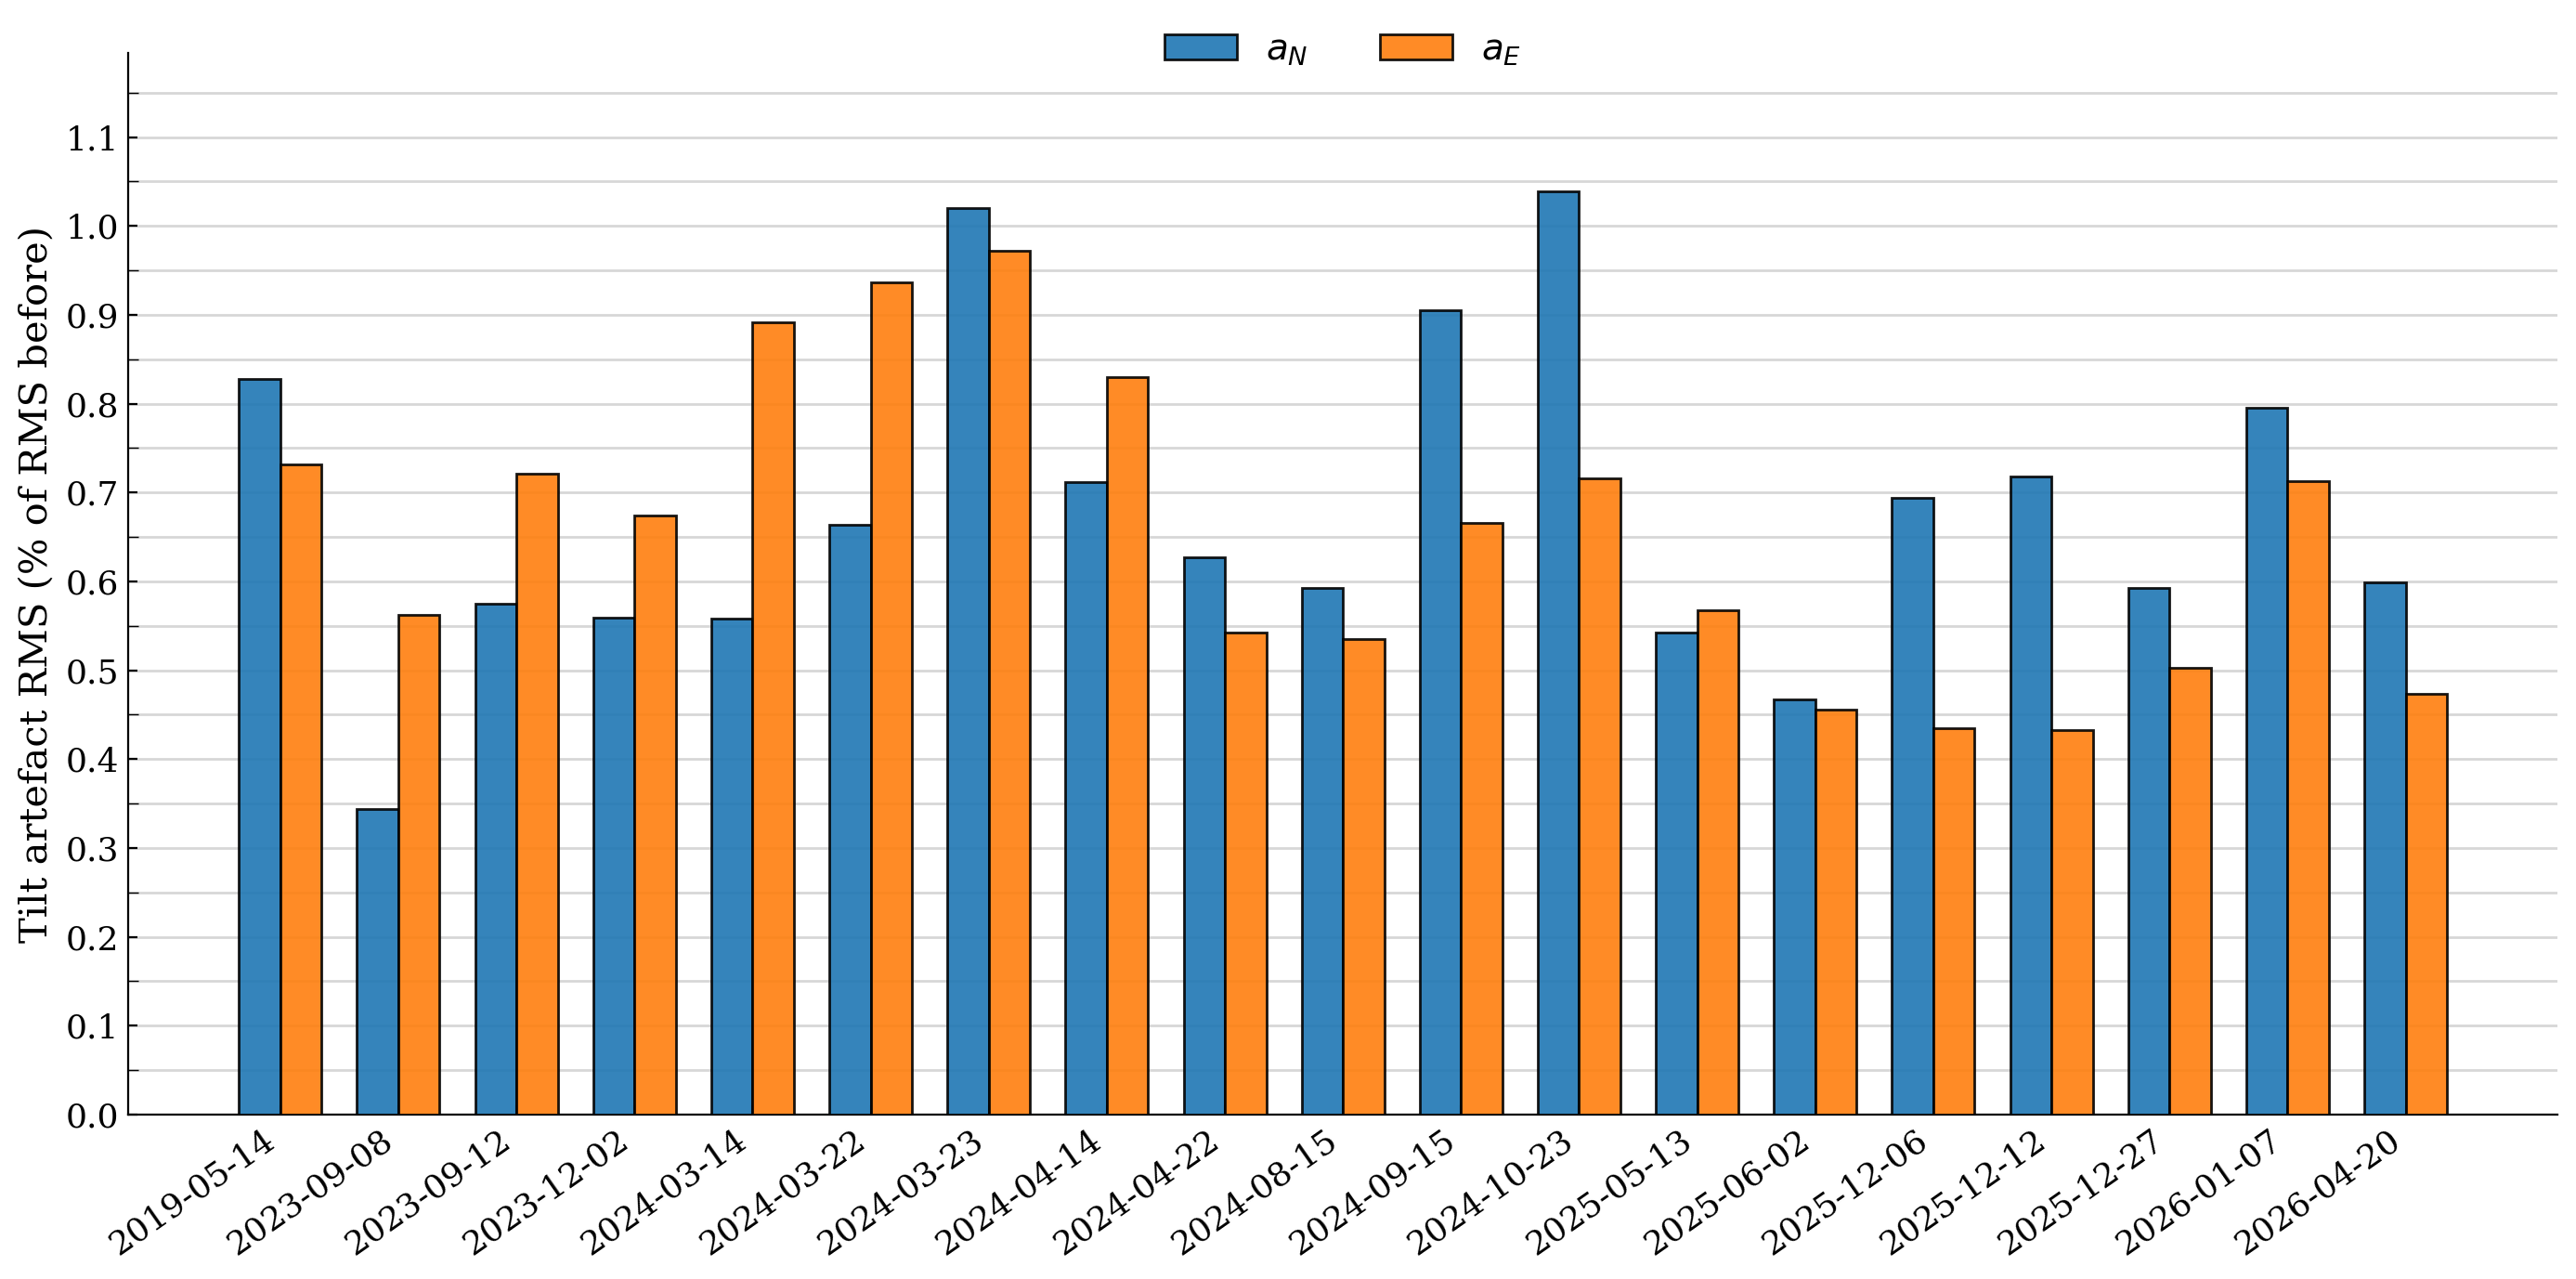

Saved: ./output/figures/tilt_correction_residual_pct.png


In [90]:
# Tilt correction residual (% of RMS before) — North and East columns per event
fig, ax = plt.subplots(figsize=(14, 7))

df_tilt = (
    df_cc.drop_duplicates(subset=['event_date'])
    .sort_values('event_date')
    .copy()
)

required_cols = [
    'rms_before_north', 'rms_residual_north',
    'rms_before_east', 'rms_residual_east',
]
missing_cols = [c for c in required_cols if c not in df_tilt.columns]
if missing_cols:
    raise ValueError(f"Missing tilt columns in {path_to_data}: {missing_cols}")

df_tilt['pct_north'] = 100.0 * df_tilt['rms_residual_north'] / df_tilt['rms_before_north']
df_tilt['pct_east'] = 100.0 * df_tilt['rms_residual_east'] / df_tilt['rms_before_east']

events = df_tilt['event_date'].values
x_base = np.arange(len(events))
width = 0.35

colors = {
    'north': 'tab:blue',
    'east': 'tab:orange',
}

offset = -0.5
for component, col, color in [
    ('north', 'pct_north', colors['north']),
    ('east', 'pct_east', colors['east']),
]:
    x_pos = []
    vals = []
    for i, event in enumerate(events):
        row = df_tilt[df_tilt['event_date'] == event]
        if len(row) > 0:
            x_pos.append(i + offset * width)
            vals.append(row[col].iloc[0])

    if len(x_pos) > 0:
        label = r'$a_N$' if component == 'north' else r'$a_E$'
        ax.bar(
            np.array(x_pos), vals, width,
            label=label, zorder=10, alpha=0.9,
            color=color, edgecolor='black', linewidth=1,
        )
    offset += 1

ymax = max(df_tilt['pct_north'].max(), df_tilt['pct_east'].max())
ytick_step = 0.1 if ymax <= 2 else 0.5
ax.set_yticks(np.arange(0, ymax * 1.25 + ytick_step, ytick_step))
ax.set_yticks(np.arange(0, ymax * 1.25 + ytick_step / 2, ytick_step / 2), minor=True)

ax.set_ylabel('Tilt artefact RMS (% of RMS before)', fontsize=15)
ax.set_xticks(x_base)
xlabels = [
    f"{str(d)[:4]}-{str(d)[4:6]}-{str(d)[6:]}" for d in events
]
ax.set_xticklabels(xlabels, rotation=35, ha='right', fontsize=15)
ax.legend(fontsize=14, loc=9, ncol=2, bbox_to_anchor=(0.5, 1.05))

ax.grid(True, alpha=0.5, axis='y', which='major', linestyle='-', linewidth=1, zorder=0)
ax.grid(True, alpha=0.5, axis='y', which='minor', linestyle='-', linewidth=1, zorder=0)

ax.set_ylim(0, ymax * 1.15)
ax.tick_params(axis='both', which='major', labelsize=13)
ax.tick_params(axis='x', which='minor', bottom=False, labelbottom=False)
ax.tick_params(axis='y', which='minor', length=4, width=0.5)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

output_file = os.path.join(output_dir, 'tilt_correction_residual_pct.png')
fig.savefig(output_file, bbox_inches='tight', dpi=150)
print(f"Saved: {output_file}")


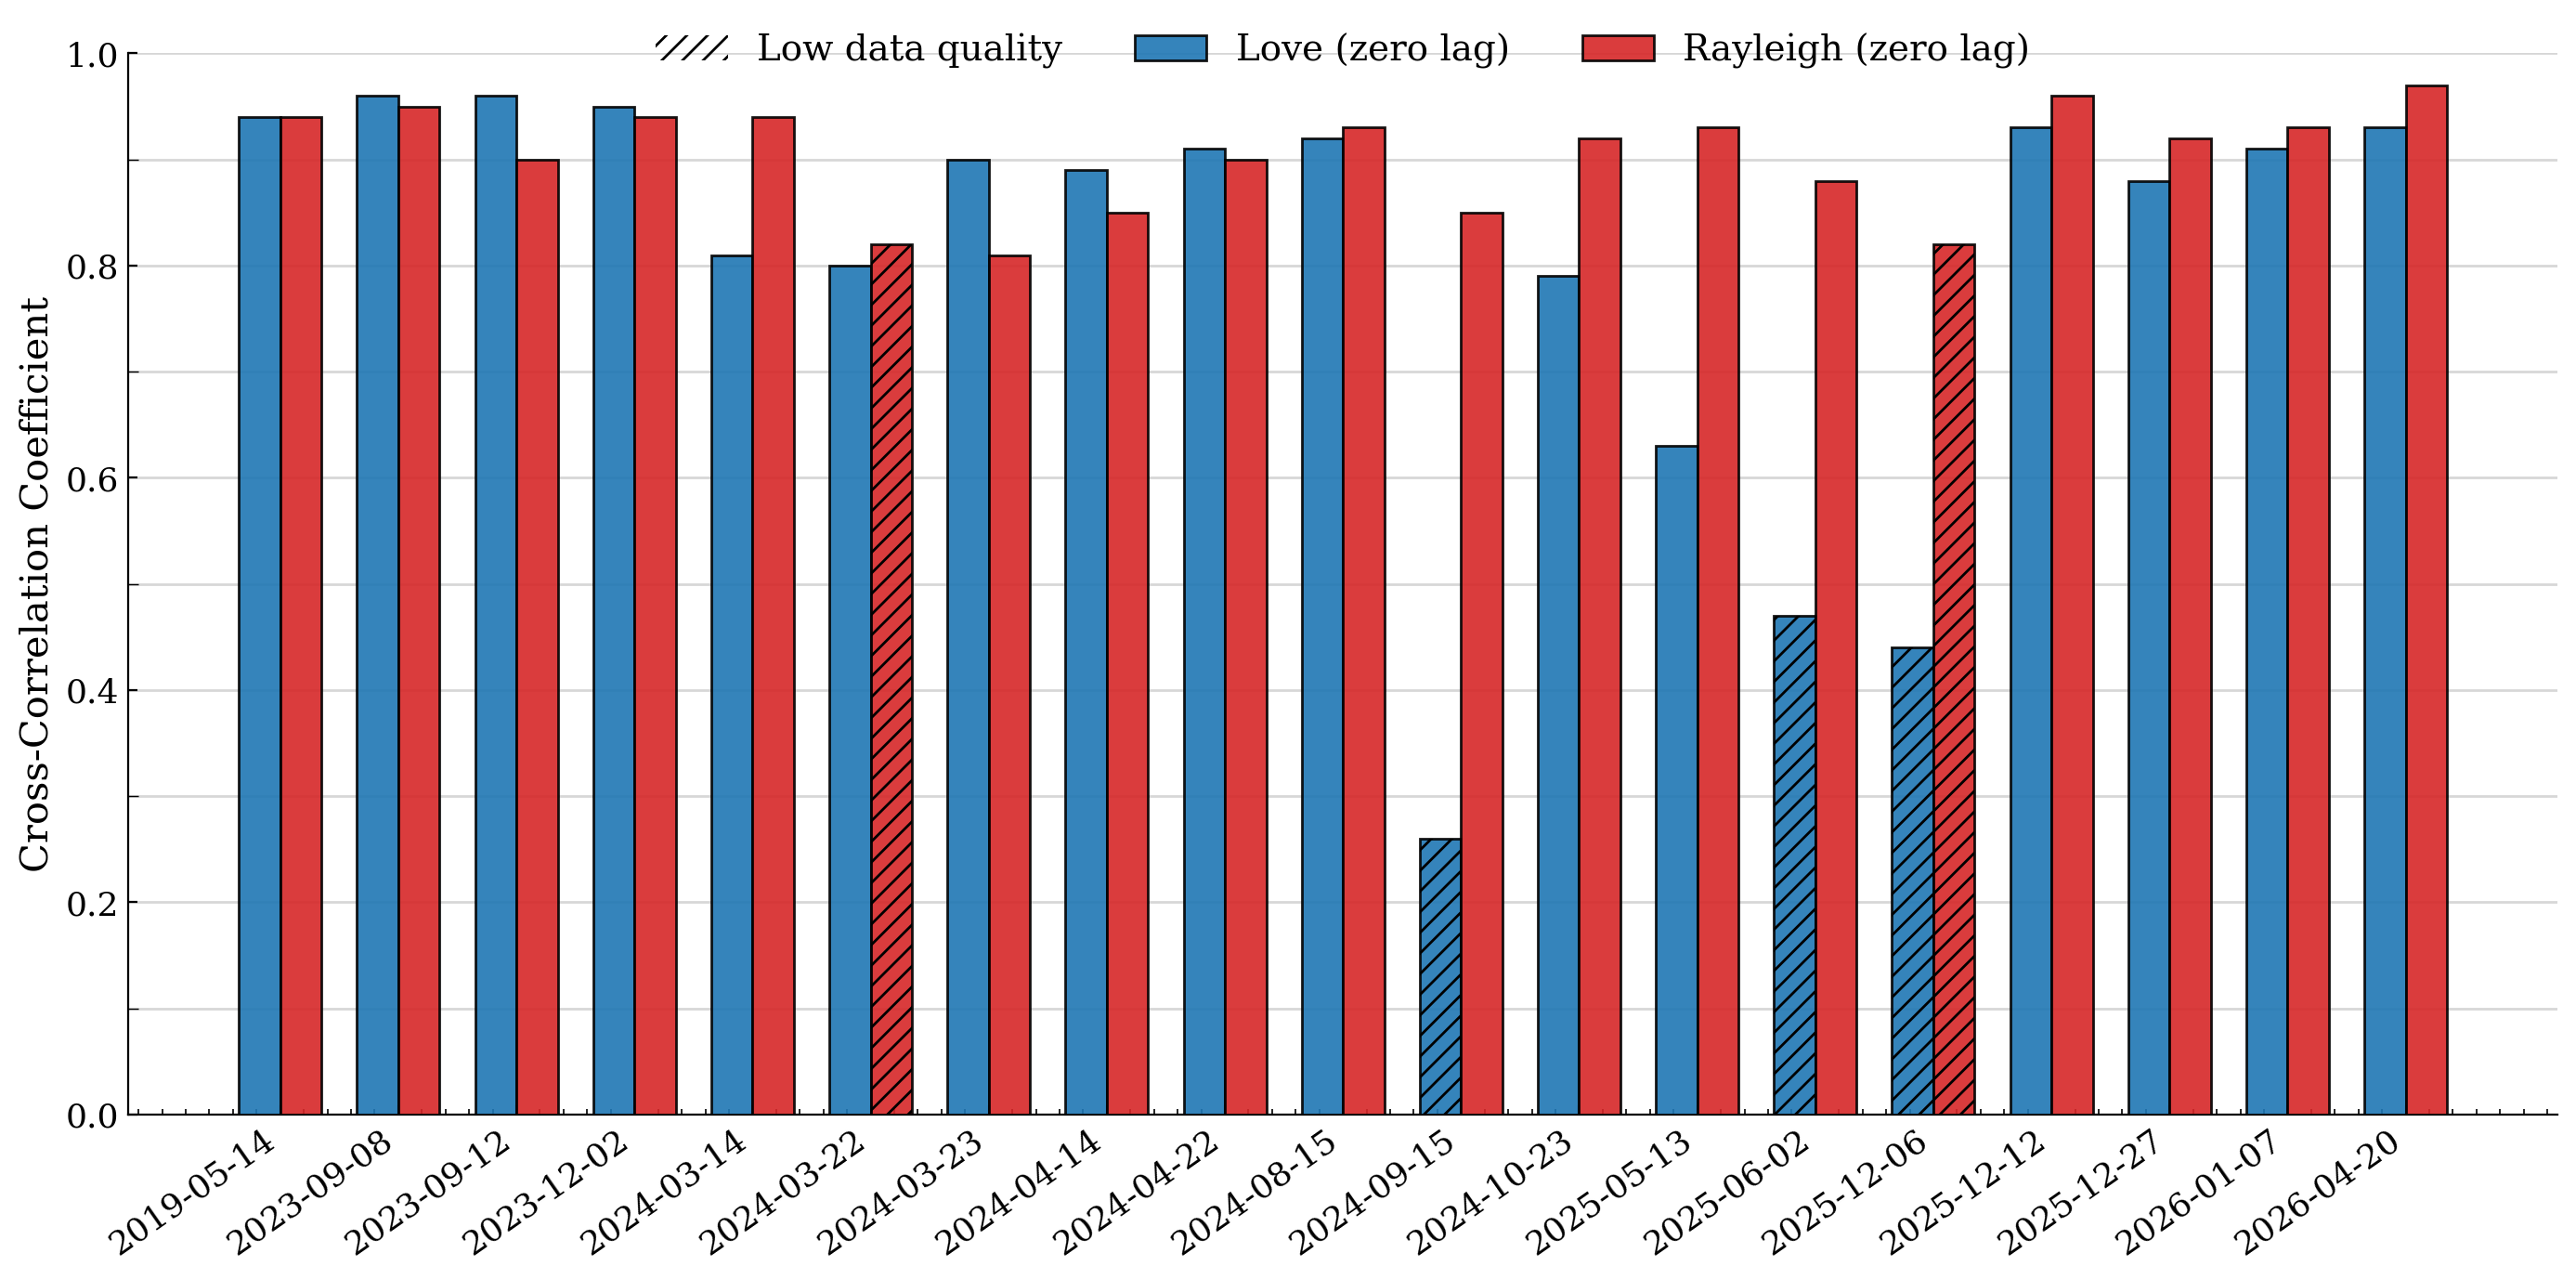

Saved: ./output/figures/correlation_comparison_all.png


In [91]:
# Combined plot for all wave types
fig, ax = plt.subplots(figsize=(14, 7))

# Get unique events
events = df_cc['event_date'].unique()
x_base = np.arange(len(events))
width = 0.35
# Colors for wave types
colors = {
    'love': 'tab:blue',
    'rayleigh': 'tab:red',
}

# Plot CC threshold
# ax.axhline(y=cc_threshold, color='gray', linestyle='--', linewidth=1.5, label='CC threshold', zorder=0)

# Mark (hatch) bars corresponding to dates with reduced quality
quality_label_added = False
for i, event in enumerate(events):
    event_int = int(event)
    if event_int in dates_love:
        love_data = df_cc[(df_cc['event_date'] == event) & (df_cc['wave_type'] == 'love')]
        if len(love_data) > 0:
            label = 'Reduced quality' if not quality_label_added else None
            ax.bar(i - 0.5 * width, love_data['cc_zero'].iloc[0], width,
                   facecolor='none', edgecolor='black', hatch='///',
                   linewidth=0.0, zorder=11, label=label)
            quality_label_added = True
    if event_int in dates_rayleigh:
        rayleigh_data = df_cc[(df_cc['event_date'] == event) & (df_cc['wave_type'] == 'rayleigh')]
        if len(rayleigh_data) > 0:
            label = 'Low data quality' if not quality_label_added else None
            ax.bar(i + 0.5 * width, rayleigh_data['cc_zero'].iloc[0], width,
                   facecolor='none', edgecolor='black', hatch='///',
                   linewidth=0.0, zorder=11, label=label)
            quality_label_added = True

# Plot each wave type
offset = -0.5
for wave_type in ['love', 'rayleigh']:
    df_wave = df_cc[df_cc['wave_type'] == wave_type].copy()
    
    if len(df_wave) > 0:
        # Zero lag bars
        x_zero = []
        cc_zero_vals = []
        for i, event in enumerate(events):
            event_data = df_wave[df_wave['event_date'] == event]
            if len(event_data) > 0:
                x_zero.append(i + offset * width)
                cc_zero_vals.append(event_data['cc_zero'].iloc[0])
        
        if len(x_zero) > 0:
            bars_zero = ax.bar(np.array(x_zero), cc_zero_vals, width, 
                              label=f'{wave_type.capitalize()} (zero lag)', zorder=10,
                              alpha=0.9, color=colors[wave_type], edgecolor='black', linewidth=1)
        
        offset += 1
        

# Set major and minor y-ticks
ax.set_yticks(np.arange(0, 1.2, 0.2))  # Major ticks every 0.2
ax.set_yticks(np.arange(0, 1.2, 0.1), minor=True)  # Minor ticks every 0.1

ax.set_ylabel('Cross-Correlation Coefficient', fontsize=15)
# ax.set_title('Cross-Correlation Comparison', fontsize=15, fontweight='bold')
ax.set_xticks(x_base)
xlables = [str(l)[:4]+"-"+str(l)[4:6]+"-"+str(l)[6:] for l in valid_data['event_date'].values]
ax.set_xticklabels(xlables, rotation=35, ha='right', fontsize=15)
ax.legend(fontsize=14, loc=9, ncol=3, bbox_to_anchor=(0.5, 1.05))

# Add gridlines for both major and minor ticks
ax.grid(True, alpha=0.5, axis='y', which='major', linestyle='-', linewidth=1, zorder=0)
ax.grid(True, alpha=0.5, axis='y', which='minor', linestyle='-', linewidth=1, zorder=0)

ax.set_ylim(0, 1.)
ax.tick_params(axis='both', which='major', labelsize=13)
ax.tick_params(axis='y', which='minor', length=4, width=0.5)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

output_file = os.path.join(output_dir, 'correlation_comparison_all.png')
fig.savefig(output_file, bbox_inches='tight', dpi=150)
print(f"Saved: {output_file}")


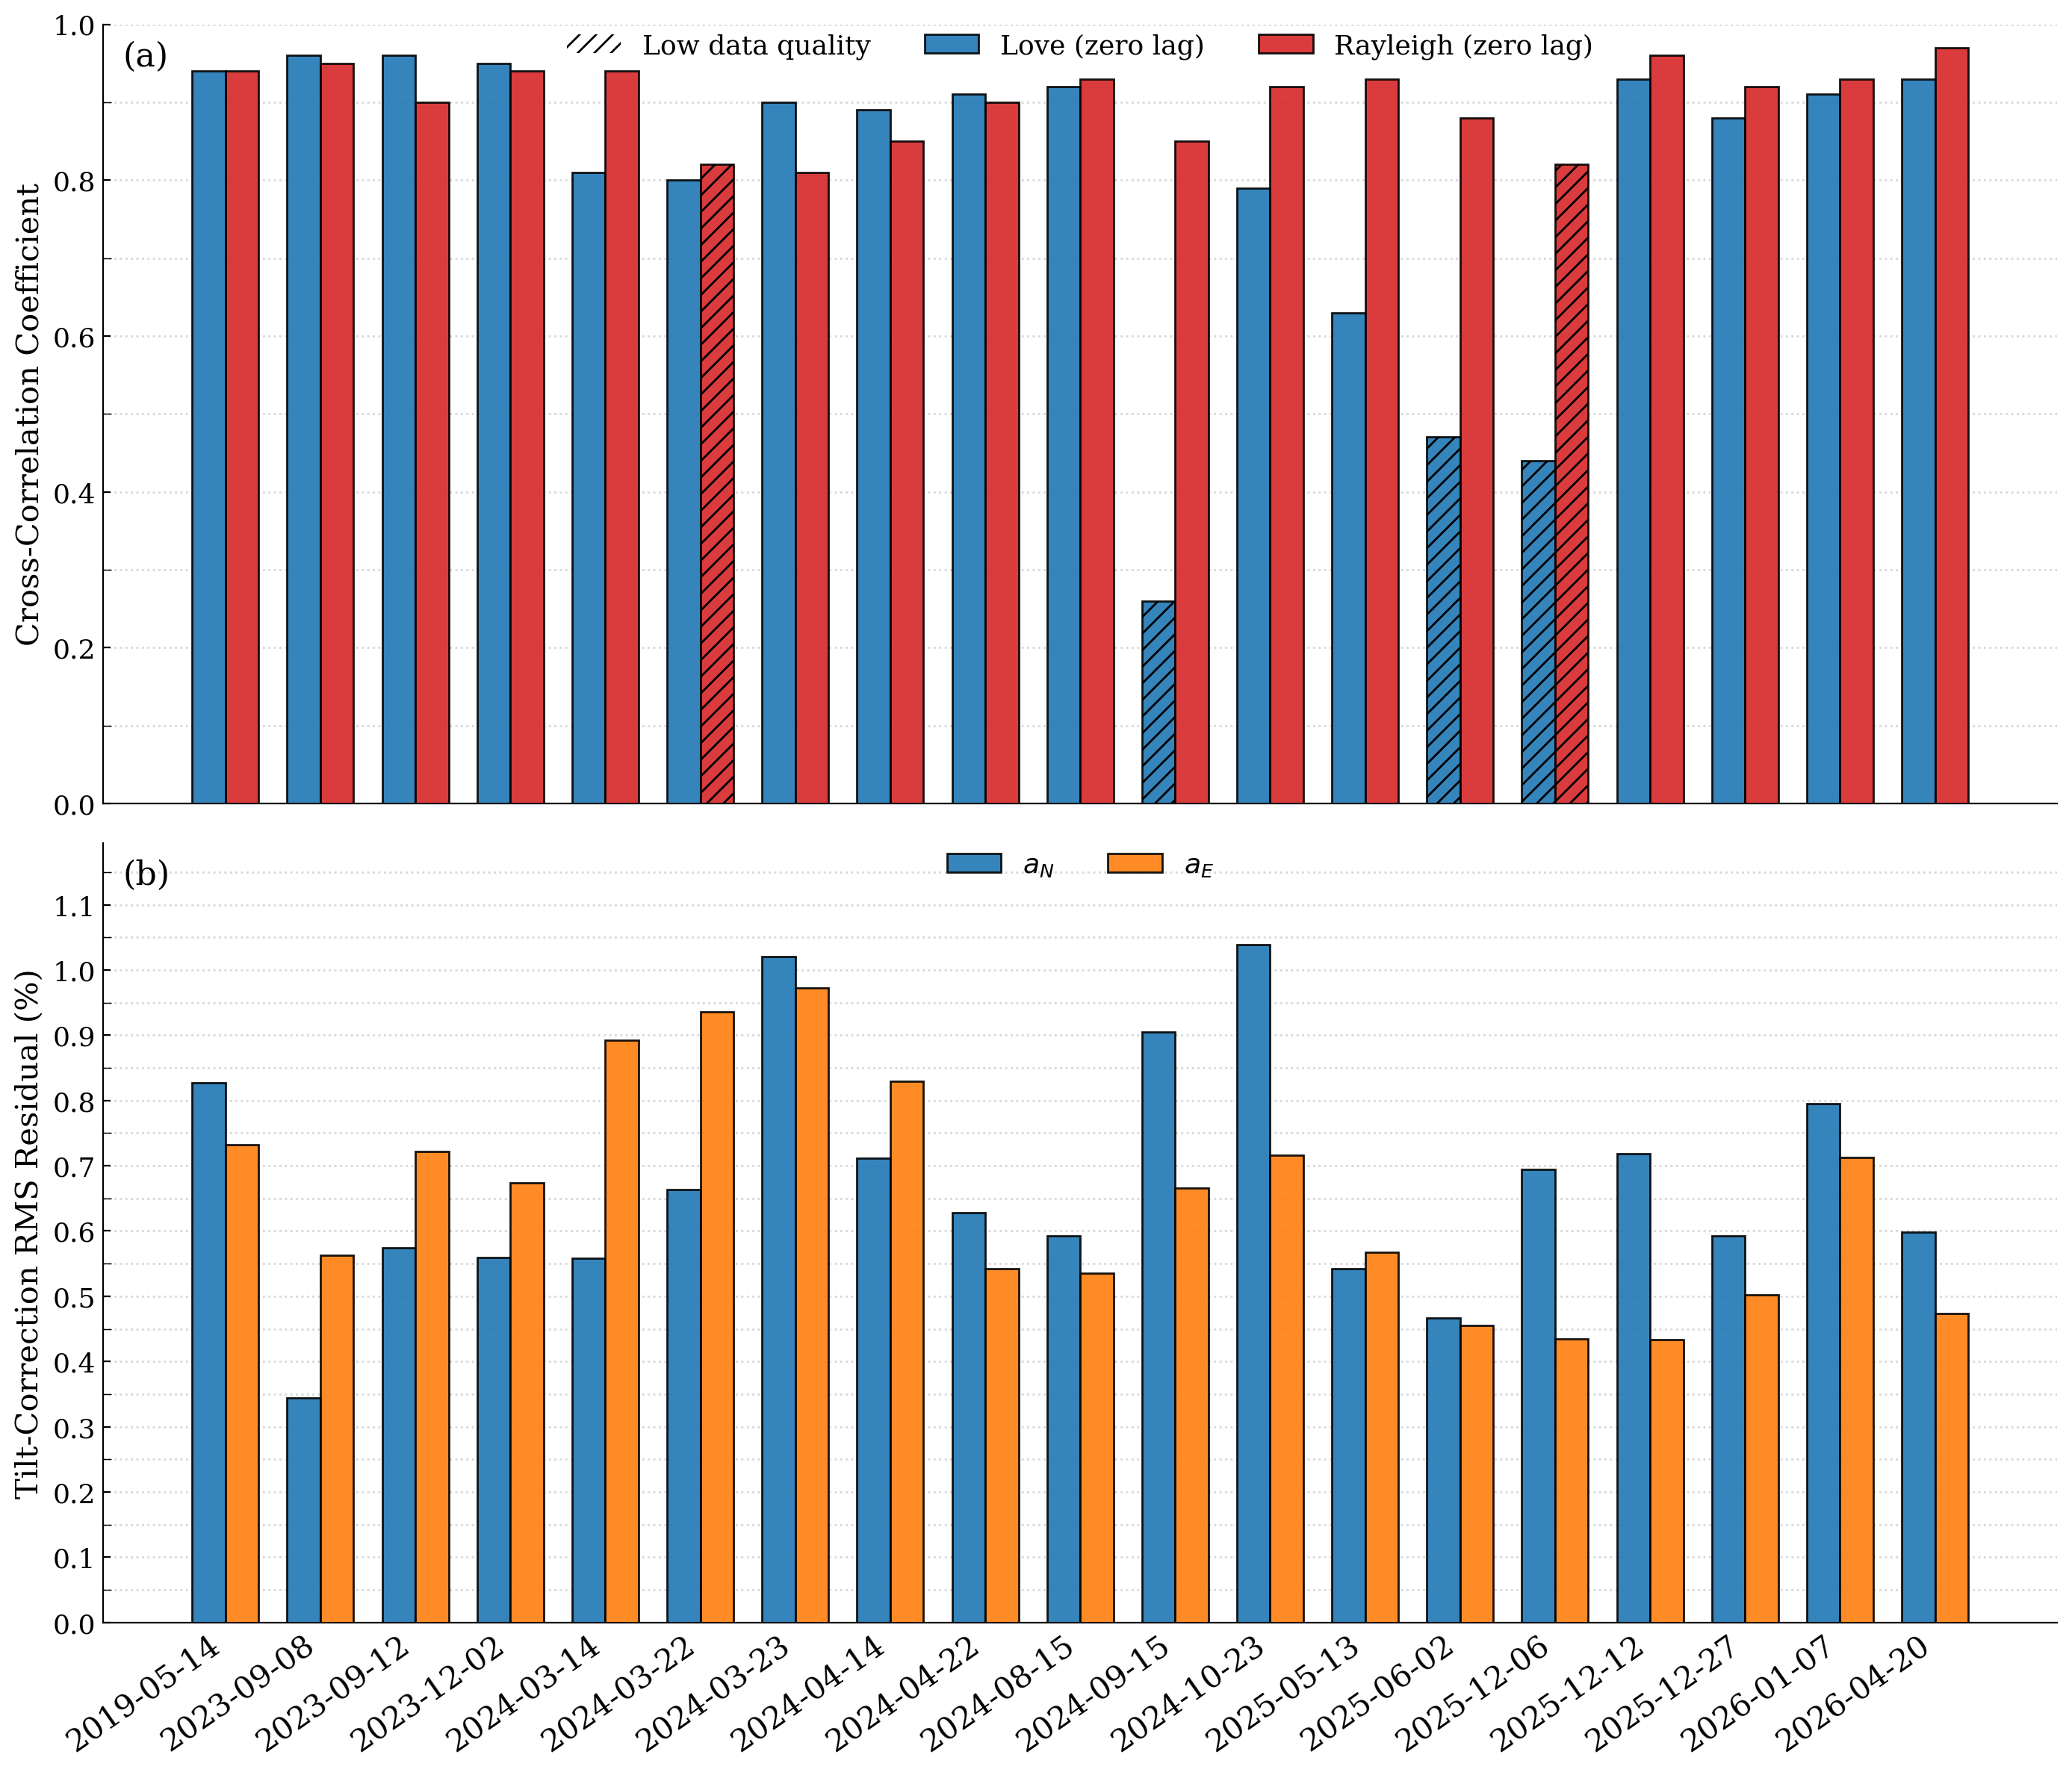

Saved: ./output/figures/correlation_tilt_combined.png


In [96]:
# Combined figure: (a) cross-correlation, (b) tilt correction residual
fig, (ax_cc, ax_tilt) = plt.subplots(2, 1, figsize=(14, 12), sharex=True)
plt.subplots_adjust(hspace=0.08)

events = np.sort(df_cc['event_date'].unique())
x_base = np.arange(len(events))
width = 0.35
xlabels = [f"{str(d)[:4]}-{str(d)[4:6]}-{str(d)[6:]}" for d in events]

# --- (a) Cross-correlation ---
cc_colors = {'love': 'tab:blue', 'rayleigh': 'tab:red'}

quality_label_added = False
for i, event in enumerate(events):
    event_int = int(event)
    if event_int in dates_love:
        love_data = df_cc[(df_cc['event_date'] == event) & (df_cc['wave_type'] == 'love')]
        if len(love_data) > 0:
            label = 'Reduced quality' if not quality_label_added else None
            ax_cc.bar(
                i - 0.5 * width, love_data['cc_zero'].iloc[0], width,
                facecolor='none', edgecolor='black', hatch='///',
                linewidth=0.0, zorder=11, label=label,
            )
            quality_label_added = True
    if event_int in dates_rayleigh:
        rayleigh_data = df_cc[(df_cc['event_date'] == event) & (df_cc['wave_type'] == 'rayleigh')]
        if len(rayleigh_data) > 0:
            label = 'Low data quality' if not quality_label_added else None
            ax_cc.bar(
                i + 0.5 * width, rayleigh_data['cc_zero'].iloc[0], width,
                facecolor='none', edgecolor='black', hatch='///',
                linewidth=0.0, zorder=11, label=label,
            )
            quality_label_added = True

offset = -0.5
for wave_type in ['love', 'rayleigh']:
    df_wave = df_cc[df_cc['wave_type'] == wave_type].copy()
    if len(df_wave) == 0:
        offset += 1
        continue

    x_zero, cc_zero_vals = [], []
    for i, event in enumerate(events):
        event_data = df_wave[df_wave['event_date'] == event]
        if len(event_data) > 0:
            x_zero.append(i + offset * width)
            cc_zero_vals.append(event_data['cc_zero'].iloc[0])

    if len(x_zero) > 0:
        ax_cc.bar(
            np.array(x_zero), cc_zero_vals, width,
            label=f'{wave_type.capitalize()} (zero lag)', zorder=10,
            alpha=0.9, color=cc_colors[wave_type], edgecolor='black', linewidth=1,
        )
    offset += 1

ax_cc.set_yticks(np.arange(0, 1.2, 0.2))
ax_cc.set_yticks(np.arange(0, 1.2, 0.1), minor=True)
ax_cc.set_ylabel('Cross-Correlation Coefficient', fontsize=15)
ax_cc.legend(fontsize=13, loc=9, ncol=3, bbox_to_anchor=(0.5, 1.02))
ax_cc.grid(True, alpha=0.5, axis='y', which='major', linestyle=':', linewidth=1, zorder=0)
ax_cc.grid(True, alpha=0.5, axis='y', which='minor', linestyle=':', linewidth=1, zorder=0)
ax_cc.set_ylim(0, 1.0)
ax_cc.tick_params(axis='both', which='major', labelsize=13)
ax_cc.tick_params(axis='x', which='minor', bottom=False, labelbottom=False)
ax_cc.tick_params(axis='y', which='minor', length=4, width=0.5)
ax_cc.spines['top'].set_visible(False)
ax_cc.spines['right'].set_visible(False)
ax_cc.text(0.01, 0.98, '(a)', transform=ax_cc.transAxes, fontsize=16, va='top', ha='left')
plt.setp(ax_cc.get_xticklabels(), visible=False)

# --- (b) Tilt correction residual ---
df_tilt = (
    df_cc.drop_duplicates(subset=['event_date'])
    .sort_values('event_date')
    .copy()
)
df_tilt['pct_north'] = 100.0 * df_tilt['rms_residual_north'] / df_tilt['rms_before_north']
df_tilt['pct_east'] = 100.0 * df_tilt['rms_residual_east'] / df_tilt['rms_before_east']

tilt_colors = {'north': 'tab:blue', 'east': 'tab:orange'}
offset = -0.5
for component, col, color in [
    ('north', 'pct_north', tilt_colors['north']),
    ('east', 'pct_east', tilt_colors['east']),
]:
    x_pos, vals = [], []
    for i, event in enumerate(events):
        row = df_tilt[df_tilt['event_date'] == event]
        if len(row) > 0:
            x_pos.append(i + offset * width)
            vals.append(row[col].iloc[0])

    if len(x_pos) > 0:
        label = r'$a_N$' if component == 'north' else r'$a_E$'
        ax_tilt.bar(
            np.array(x_pos), vals, width,
            label=label, zorder=10, alpha=0.9,
            color=color, edgecolor='black', linewidth=1,
        )
    offset += 1

ymax = max(df_tilt['pct_north'].max(), df_tilt['pct_east'].max())
ytick_step = 0.1 if ymax <= 2 else 0.5
ax_tilt.set_yticks(np.arange(0, ymax * 1.25 + ytick_step, ytick_step))
ax_tilt.set_yticks(np.arange(0, ymax * 1.25 + ytick_step / 2, ytick_step / 2), minor=True)
ax_tilt.set_ylabel('Tilt-Correction RMS Residual (%)', fontsize=15)
ax_tilt.legend(fontsize=13, loc=9, ncol=2, bbox_to_anchor=(0.5, 1.02))
ax_tilt.grid(True, alpha=0.5, axis='y', which='major', linestyle=':', linewidth=1, zorder=0)
ax_tilt.grid(True, alpha=0.5, axis='y', which='minor', linestyle=':', linewidth=1, zorder=0)
ax_tilt.set_ylim(0, ymax * 1.15)
ax_tilt.tick_params(axis='both', which='major', labelsize=13)
ax_tilt.tick_params(axis='x', which='minor', bottom=False, labelbottom=False)
ax_tilt.tick_params(axis='y', which='minor', length=4, width=0.5)
ax_tilt.spines['top'].set_visible(False)
ax_tilt.spines['right'].set_visible(False)
ax_tilt.text(0.01, 0.98, '(b)', transform=ax_tilt.transAxes, fontsize=16, va='top', ha='left')

ax_tilt.set_xticks(x_base)
ax_tilt.set_xticklabels(xlabels, rotation=35, ha='right', fontsize=15)

plt.tight_layout()
plt.show()

output_file = os.path.join(output_dir, 'correlation_tilt_combined.png')
fig.savefig(output_file, bbox_inches='tight', dpi=150)
print(f"Saved: {output_file}")
